# LGN phosphene simulator: a guided tour

`dynaphos_lgn` simulates what a patient would see when electrodes in the **lateral geniculate nucleus (LGN)** are stimulated. Unlike the cortical Dynaphos simulator, you do not choose where the phosphenes appear. Each electrode sits in a voxel of a reconstructed macaque LGN atlas (Erwin et al., 1999), and the atlas decides the phosphene's position, size and shape.

**Contents**

1. Build a simulator and render one frame
2. One nucleus or two
3. Stimulation parameters: current and pulse width
4. Model parameters: the constant K and the magnification model
5. Placing electrodes yourself
6. Inside the simulator
7. From camera image to phosphenes
8. Optimizing the stimulation
9. Koniocellular cells
10. Color
11. Electrode level or tissue level

Throughout, the simulator covers **both** nuclei, and so the whole visual field. `demo_simulator_lgn.ipynb` has the long version of every section, including a switch to run everything with a single nucleus.

> **Treat the pictures as a working model, not as measurements.** Almost nothing about LGN stimulation has been measured. The current-spread constant is borrowed from macaque V1, the temporal dynamics from human V1, and the right nucleus is the left one mirrored. `dynaphos_lgn/README.md` lists the known gaps.

## 0. Setup

Every simulator in this notebook is built by `make_simulator`. It loads the shipped config, applies a handful of settings, and calls `build_simulator`, the library's single entry point. `render` stimulates every electrode at the same current and returns one frame.

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch

from dynaphos import utils
from dynaphos.image_processing import sobel_processor
from dynaphos.utils import to_numpy

from dynaphos_lgn.build import build_simulator

CONFIG = '../dynaphos_lgn/config/params_lgn.yaml'
ATLAS_DIR = '../data/Erwin_Atlas'      # the .DAT files and JACOBIAN.npz
COLORS = {'left': 'tab:blue', 'right': 'tab:red'}


def load_config(**overrides):
    """The shipped config, with `section__key=value` overrides.

    e.g. load_config(current_spread__k_ua_per_mm2=6750)
    """
    params = utils.load_params(CONFIG)
    params['atlas']['hemispheres'] = ['left', 'right']    # whole field
    # params['electrodes']['max_eccentricity_deg'] = 8.0    # fill the frame
    params['run']['fps'] = 10                             # 1 frame = 100 ms
    for key, value in overrides.items():
        *sections, name = key.split('__')
        node = params
        for section in sections:
            node = node[section]
        node[name] = value
    return params


def make_simulator(n_electrodes=100, **overrides):
    """Build a simulator with `n_electrodes` in EACH nucleus."""
    params = load_config(electrodes__n_electrodes=n_electrodes, **overrides)
    return build_simulator(params, atlas_dir=ATLAS_DIR)


def render(simulator, current_ua=100.):
    """One frame with every electrode at `current_ua`."""
    simulator.reset()
    return simulator(current_ua * 1e-6 * torch.ones(simulator.num_phosphenes))


HALF = load_config()['run']['view_angle'] / 2
EXTENT = [-HALF, HALF, -HALF, HALF]            # image axes in degrees


def show(ax, image, title=''):
    """A rendered frame, with axes in degrees of visual angle."""
    ax.imshow(to_numpy(image), cmap='gray', origin='lower',
              vmin=0, vmax=1, extent=EXTENT)
    ax.set(title=title, xlabel='x (deg)', ylabel='y (deg)')

## 1. Build a simulator and render one frame

`build_simulator` does the whole chain: load the atlas, place the electrodes, look up each phosphene's position and size, and return a ready simulator. With two nuclei it returns a `BilateralLGNSimulator`, which holds one simulator per nucleus and adds their images together.

By default the electrodes are spread evenly over the visual field. `n_electrodes` counts **per nucleus**, and every per-electrode vector lists the left nucleus first.

In [3]:
simulator, parts = make_simulator(n_electrodes=100)

print(type(simulator).__name__, '-', simulator.num_phosphenes, 'electrodes')
for name, span in simulator.electrode_slices.items():
    print(f'  {name:<5} nucleus: electrodes {span.start}-{span.stop - 1}')

BilateralLGNSimulator - 200 electrodes
  left  nucleus: electrodes 0-99
  right nucleus: electrodes 100-199


The simulator takes one current per electrode (in amperes) and returns an image. `reset()` clears its memory of earlier frames.

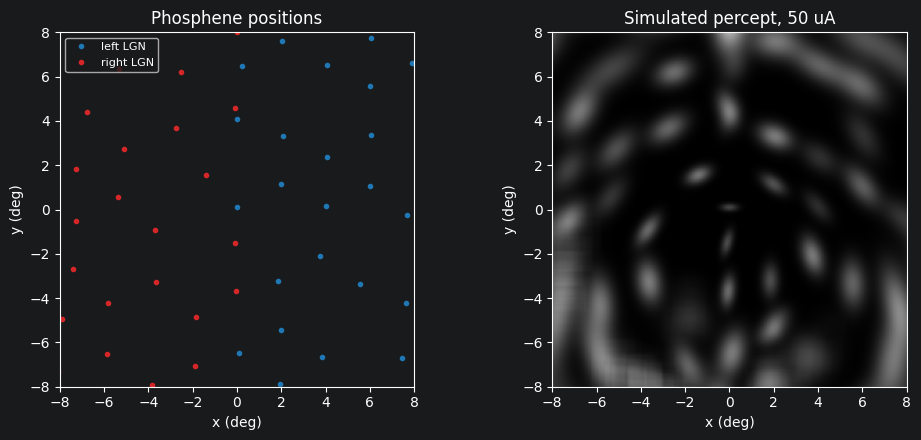

In [4]:
amplitude = 50e-6   # amperes
stim = amplitude * torch.ones(simulator.num_phosphenes)
simulator.reset()
frame = simulator(stim)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
xy = simulator.vf_xy
for name, span in simulator.electrode_slices.items():
    axs[0].plot(*xy[span].T, '.', color=COLORS[name], label=f'{name} LGN')
axs[0].set(xlim=EXTENT[:2], ylim=EXTENT[2:], aspect='equal',
           xlabel='x (deg)', ylabel='y (deg)', title='Phosphene positions')
axs[0].legend(fontsize=8)
show(axs[1], frame, f'Simulated percept, {int(amplitude * 1e6)} uA')
fig.tight_layout()

Each nucleus fills one half of the field: the left LGN sees the right half, and the right LGN the left half. At 50 µA the center of the field stays dark while its edges are lit. A lone electrode needs about 52 µA before any charge reaches the tissue (section 3b), so on their own none of these phosphenes would be seen. Near the fovea the electrodes sit far apart in the tissue and do act alone. Further out, the same visual-field spacing packs them closer together in the tissue, their fields add up, and they merge into large bright patches (section 11). Sections 3 and 4 look at phosphene size.

## 2. One nucleus or two

One LGN represents only the opposite half of the visual field. The atlas is a single left nucleus, so on its own it covers the right half of the field only. The right nucleus is built by mirroring the left one.

Which nuclei are simulated is one config key, `atlas.hemispheres`. It can also be passed straight to `build_simulator`:

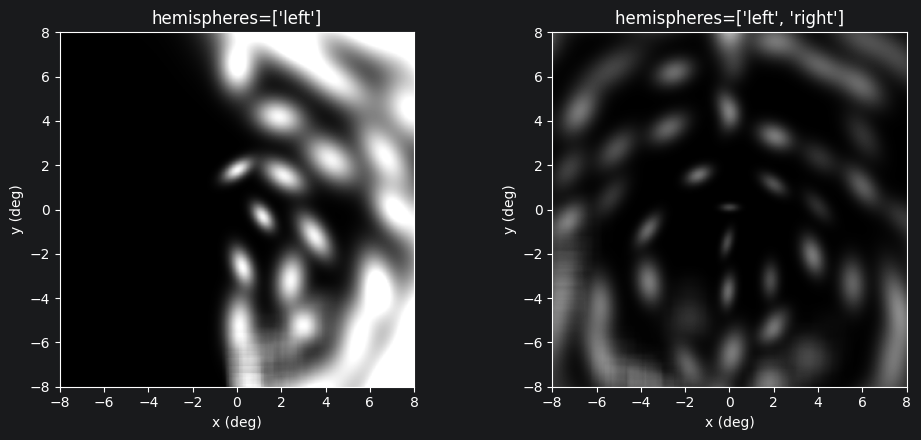

In [5]:
one_nucleus, _ = build_simulator(load_config(electrodes__n_electrodes=100),
                                 atlas_dir=ATLAS_DIR, hemispheres=['left'])

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
show(axs[0], render(one_nucleus), "hemispheres=['left']")
show(axs[1], frame, "hemispheres=['left', 'right']")
fig.tight_layout()

With one nucleus the left half of every frame stays black. Keep in mind that the two halves are **not independent**: they are the same tissue reflected, so any quirk of the atlas appears in both, mirrored.

## 3. Stimulation parameters

Each electrode is driven by three numbers: amplitude, pulse width and frequency. Each can be one value per electrode, or a single number for all of them. This section sweeps them on the 100-per-nucleus array from section 1.

#### 3a. Current: size against spacing

Two electrodes look like two separate spots only while they are more than about **2σ apart** (Sparrow's criterion). The spacing is fixed by where the electrodes are, but σ depends on the current: less current recruits less tissue, so the phosphene is smaller. It is also dimmer, and below threshold it is not seen at all.

   uA  sigma (deg)  resolvable  detected
   30         1.22         47%        0%
   50         1.57         30%       58%
   70         1.86         19%       98%
  100         2.22         14%      100%

Median spacing 2.24 deg. "resolvable": nearest neighbour > 2 sigma away. "detected": p(detect) > 0.5.


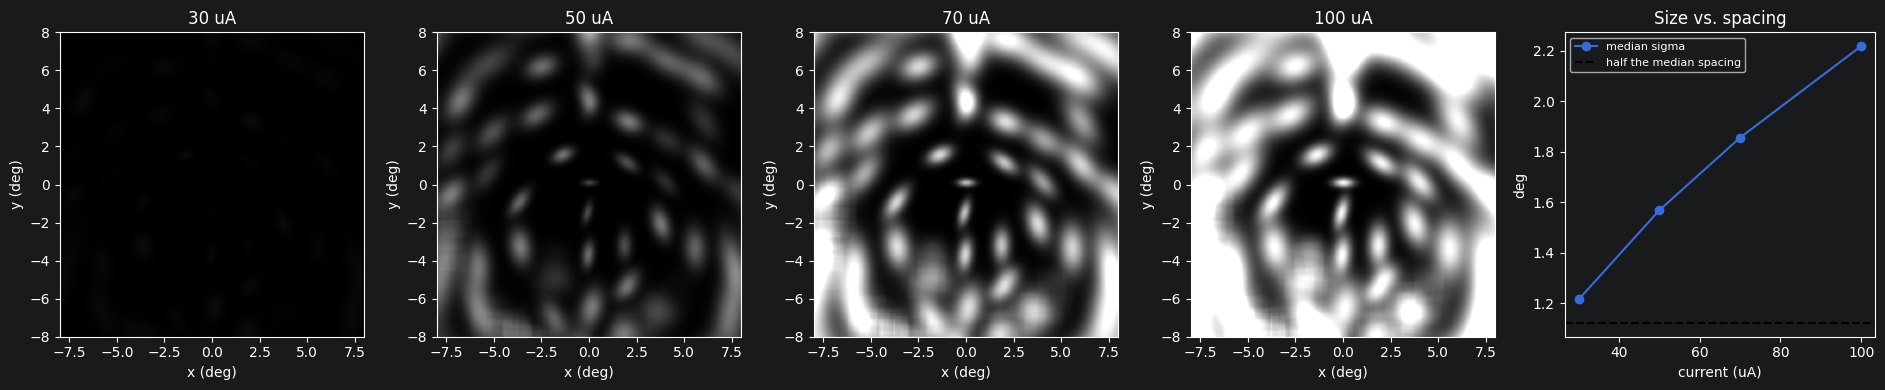

In [6]:
AMPLITUDES_UA = [30., 50., 70., 100.]   # max_current_ua in the config is 100

xy = simulator.vf_xy
distance = np.linalg.norm(xy[:, None] - xy[None, :], axis=-1)
np.fill_diagonal(distance, np.inf)
spacing = distance.min(axis=1)          # nearest-neighbor spacing, deg

fig, axs = plt.subplots(1, len(AMPLITUDES_UA) + 1, figsize=(19, 4))
sigmas = []
print(f'{"uA":>5} {"sigma (deg)":>12} {"resolvable":>11} {"detected":>9}')
for ax, amplitude in zip(axs, AMPLITUDES_UA):
    image = render(simulator, amplitude)
    major, _ = simulator.phosphene_sigma_deg(amplitude)
    detected = to_numpy(simulator.get_state()['detection_probability']).ravel()
    resolvable = 100 * np.mean(spacing > 2 * major)
    sigmas.append(np.nanmedian(major))
    show(ax, image, f'{amplitude:.0f} uA')
    print(f'{amplitude:5.0f} {sigmas[-1]:12.2f} {resolvable:10.0f}% '
          f'{100 * np.mean(detected > 0.5):8.0f}%')

axs[-1].plot(AMPLITUDES_UA, sigmas, 'o-', label='median sigma')
axs[-1].axhline(np.median(spacing) / 2, color='k', ls='--',
                label='half the median spacing')
axs[-1].set(xlabel='current (uA)', ylabel='deg', title='Size vs. spacing')
axs[-1].legend(fontsize=8)
fig.tight_layout()
print(f'\nMedian spacing {np.median(spacing):.2f} deg. "resolvable": nearest '
      f'neighbor > 2 sigma away. "detected": p(detect) > 0.5.')

**Lowering the current does not separate them.** At 100 µA only 14% of electrodes are resolvable, and at 30 µA that rises to 47%. The electrodes are a median 2.24° apart, and σ (1.22° at 30 µA) never drops below half of that. Lower currents also leave the center dark, where the electrodes act alone and stay below the 52 µA they need (section 1). The 64% detected at 30 µA lie mostly further out, where neighboring fields add up. With this array, current alone cannot make the phosphenes distinct.

#### 3b. Pulse width: brightness and threshold, not size

Longer pulses deliver more charge per second, so the phosphenes get brighter. They also lower the threshold. The current at which charge starts to reach the tissue is `rheobase × (1 + chronaxie / pulse width)`: 52 µA at 170 µs, 36 µA at 400 µs and 30 µA at 800 µs. Phosphene size is set by the amplitude alone, so it stays the same.

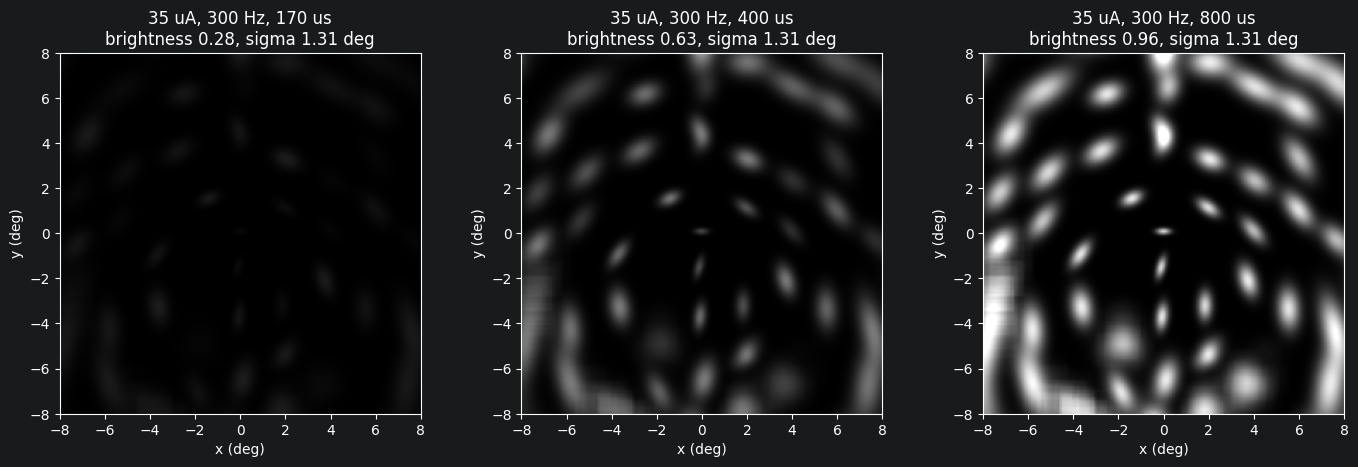

In [7]:
PULSE_WIDTHS = [170e-6, 400e-6, 800e-6]      # seconds

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, pw in zip(axs, PULSE_WIDTHS):
    simulator.reset()
    image = simulator(35e-6 * torch.ones(simulator.num_phosphenes),
                      pw, 300.)                 # amplitude, pulse width, Hz
    state = simulator.get_state()
    show(ax, image, f'35 uA, 300 Hz, {pw * 1e6:.0f} us\n'
                    f'brightness {to_numpy(state["brightness"]).mean():.2f}, '
                    f'sigma {np.nanmedian(to_numpy(state["sigma_major"])):.2f} deg')
fig.tight_layout()

At 35 µA the central phosphenes appear only with the 800 µs pulse, the one setting where 35 µA is above the threshold. Frequency changes brightness the same way, but not the threshold. The temporal model is carried over unchanged from V1, and the 200 µs chronaxie is an assumption: there is no strength-duration data for LGN at all, so the pulse-width dependence is borrowed, not measured.

## 4. Model parameters

Section 3 varied how the electrodes are driven. This section varies two assumptions inside the model instead. Both change phosphene size, and neither is well constrained for LGN. It uses 25 electrodes per nucleus so the individual phosphenes can be told apart.

#### 4a. The excitability constant K

In the model, σ scales as `sqrt(current / K)`. K = 675 µA/mm² is borrowed from macaque V1 and has never been measured in LGN; it is the least certain number in the model. The electrodes are placed before any current flows, so changing K leaves them where they are and changes only the phosphene size. The values below are a factor of ten apart and are not proposals. They show how much of the blur this one borrowed constant controls.

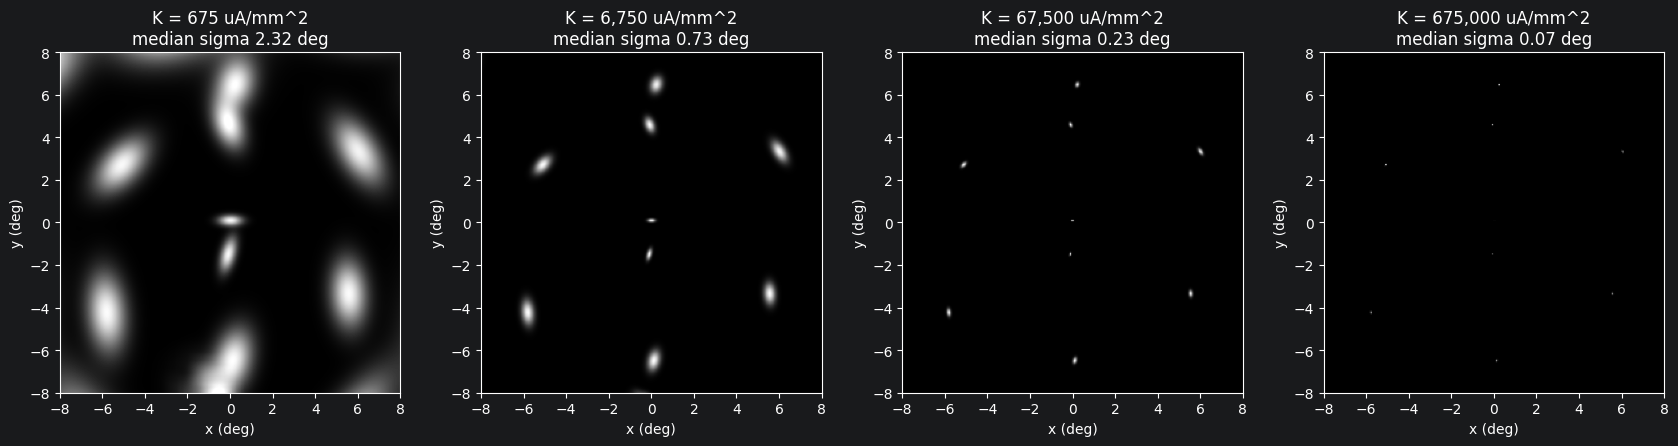

In [8]:
K_VALUES = [675., 6_750., 67_500., 675_000.]    # 675 is the shipped value

sparse, _ = make_simulator(n_electrodes=25)      # shipped K, reused in 4b

fig, axs = plt.subplots(1, len(K_VALUES), figsize=(17, 4.2))
for ax, k in zip(axs, K_VALUES):
    sim_k = sparse if k == 675. else make_simulator(
        n_electrodes=25, current_spread__k_ua_per_mm2=k)[0]
    major, _ = sim_k.phosphene_sigma_deg(100.)
    show(ax, render(sim_k), f'K = {k:,.0f} uA/mm^2\n'
                            f'median sigma {np.nanmedian(major):.2f} deg')
fig.tight_layout()

At the shipped K the phosphenes are large, soft blobs. Ten times larger K already separates them, and shows that each phosphene is an **ellipse**, not a disc. The atlas stretches visual space differently in different directions, and each ellipse's elongation and orientation are read from the tissue at its electrode.

The simulated sizes also run 4–6× larger than an independent estimate (Vurro et al., 2014). So read any "how many electrodes are usable" answer as a property of this K, not of the LGN.


## 5. Placing electrodes yourself

There are two ways to place electrodes by hand instead of spreading them automatically.

#### 5a. By position in the tissue

`voxel_indices` takes atlas voxels, one entry per nucleus. Below, the same 6 × 6 grid (0.4 mm pitch) goes into each nucleus. Distance is measured from the midline, so the same coordinates land on mirror-image tissue.

left  LGN: 34 of 36 grid points on tissue
right LGN: 34 of 36 grid points on tissue


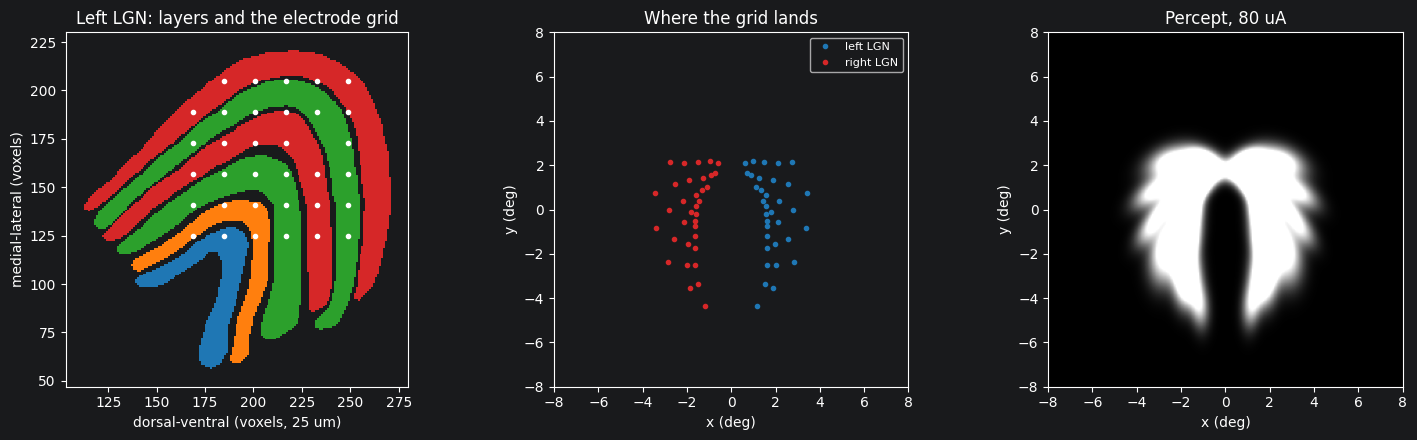

In [10]:
atlases = {name: part['atlas'] for name, part in parts['hemispheres'].items()}

# Center the grid on the atlas's representation of the central 5 degrees.
left = atlases['left']
central = np.argwhere(left.valid & ~left.is_ipsi_sentinel()
                      & (left.eccentricity_deg <= 5))
ml0, dv0, ap0 = left.index_to_horsley_clarke(*central.mean(axis=0))
offsets = (np.arange(6) - 2.5) * 0.4                     # mm
ml, dv = np.meshgrid(ml0 + offsets, dv0 + offsets, indexing='ij')

voxels = {}
for name, atlas in atlases.items():
    index = np.stack(atlas.horsley_clarke_to_index(
        ml.ravel(), dv.ravel(), np.full(ml.size, ap0), hemisphere=name), -1)
    # Drop grid points that miss the reconstructed tissue.
    usable = (atlas.valid[tuple(index.T)]
              & ~atlas.is_ipsi_sentinel(atlas.inclination[tuple(index.T)]))
    voxels[name] = index[usable]
    print(f'{name:<5} LGN: {usable.sum()} of {usable.size} grid points on tissue')

grid_sim, _ = build_simulator(load_config(), atlas_dir=ATLAS_DIR,
                              voxel_indices=voxels)

# A coronal slice of the left nucleus, colored by layer, with the grid on it
k = voxels['left'][0, 2]
layers = np.where(left.valid[:, :, k], left.layer[:, :, k], np.nan)
rows, cols = np.nonzero(left.valid[:, :, k])

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
axs[0].imshow(layers, origin='lower', cmap='tab10', vmin=0.5, vmax=10.5,
              interpolation='nearest')
axs[0].plot(voxels['left'][:, 1], voxels['left'][:, 0], 'w.', markersize=6)
axs[0].set(xlim=(cols.min() - 10, cols.max() + 10),
           ylim=(rows.min() - 10, rows.max() + 10),
           xlabel='dorsal-ventral (voxels, 25 um)',
           ylabel='medial-lateral (voxels)',
           title='Left LGN: layers and the electrode grid')
xy = grid_sim.vf_xy
for name, span in grid_sim.electrode_slices.items():
    axs[1].plot(*xy[span].T, '.', color=COLORS[name], label=f'{name} LGN')
axs[1].set(xlim=EXTENT[:2], ylim=EXTENT[2:], aspect='equal',
           xlabel='x (deg)', ylabel='y (deg)', title='Where the grid lands')
axs[1].legend(fontsize=8)
show(axs[2], render(grid_sim, 80.), 'Percept, 80 uA')
fig.tight_layout()

A regular grid in the tissue is **not** regular in the visual field. It is dense near the fovea, sparse further out, and folded where it crosses a layer boundary. The colored bands are the atlas's layers: two magnocellular and two parvocellular codes, one per eye.

#### 5b. By position in the visual field

`visual_field_targets` works the other way round. You give (eccentricity, inclination) positions in degrees, and each electrode goes to the voxel that best matches one of them. Each target is sent to the nucleus that covers its half of the field. The match is the nearest voxel, so `position_error_deg` reports how far off each one landed.

left  LGN: 3 targets, miss 0.00, 0.00, 0.00 deg
right LGN: 5 targets, miss 0.00, 0.00, 0.00, 0.00, 0.00 deg


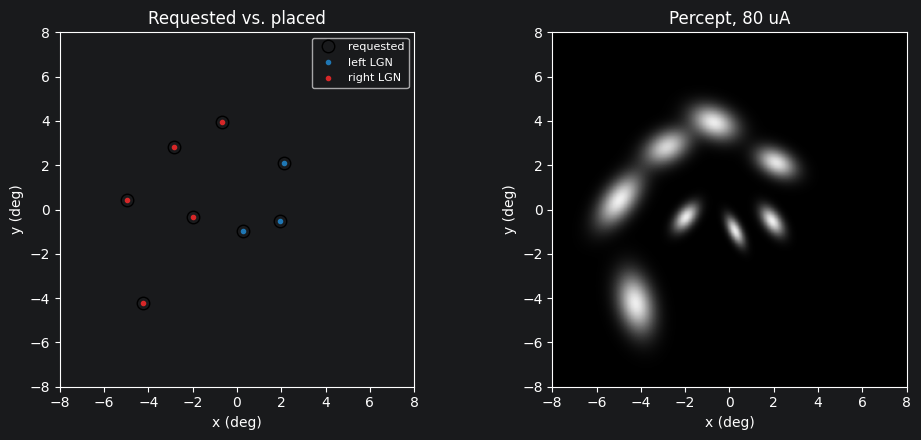

In [11]:
eccentricity = np.array([1., 2., 3., 4., 5., 6., 2., 4.])
inclination = np.array([-75., -15., 45., 135., 175., -135., -170., 100.])

target_sim, target_parts = build_simulator(
    load_config(), atlas_dir=ATLAS_DIR,
    visual_field_targets=(eccentricity, inclination))

for name, part in target_parts['hemispheres'].items():
    errors = part['electrode_array'].position_error_deg
    print(f'{name:<5} LGN: {len(errors)} targets, miss '
          + ', '.join(f'{e:.2f}' for e in errors) + ' deg')

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
requested = eccentricity * np.stack([np.cos(np.deg2rad(inclination)),
                                     np.sin(np.deg2rad(inclination))])
axs[0].plot(*requested, 'ko', fillstyle='none', markersize=9, label='requested')
xy = target_sim.vf_xy
for name, span in target_sim.electrode_slices.items():
    axs[0].plot(*xy[span].T, '.', color=COLORS[name], label=f'{name} LGN')
axs[0].set(xlim=EXTENT[:2], ylim=EXTENT[2:], aspect='equal',
           xlabel='x (deg)', ylabel='y (deg)', title='Requested vs. placed')
axs[0].legend(fontsize=8)
show(axs[1], render(target_sim, 80.), 'Percept, 80 uA')
fig.tight_layout()

## 6. Inside the simulator

`get_state()` returns every internal quantity, one row per electrode, left nucleus first. Three entries are specific to LGN:

- `sigma_major` / `sigma_minor`: the two axes of each phosphene ellipse, in degrees.
- `layer_activation`: how much of each LGN layer the current reached, which `layer_activation_table()` breaks down by layer.
- `equivalent_current_ua`: the current each electrode acts with once its neighbors' fields are added (section 11).

A small array (3 electrodes per nucleus) keeps the output readable.

get_state() keys: brightness, sigma_major, sigma_minor, activation, trace, threshold, detection_probability, effective_charge_per_second, layer_activation, recruited_cells, class_fraction
electrode    : ['left', 'left', 'left', 'right', 'right', 'right']
brightness   : [0.986 0.99  0.35  0.993 0.367 0.819]
sigma major  : [2.46 3.45 1.57 1.72 2.06 2.  ]
sigma minor  : [1.84 2.29 0.79 1.09 1.4  1.46]


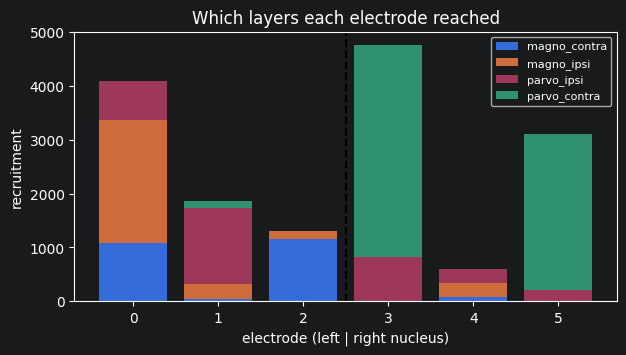

In [12]:
small, _ = make_simulator(n_electrodes=3)
small.reset()
small(100e-6 * torch.rand(small.num_phosphenes))

state = small.get_state()
print('get_state() keys:', ', '.join(state))
print('electrode    :', list(small.hemisphere_of_electrode))
print('brightness   :', np.round(to_numpy(state['brightness']).ravel(), 3))
print('sigma major  :', np.round(to_numpy(state['sigma_major']).ravel(), 2))
print('sigma minor  :', np.round(to_numpy(state['sigma_minor']).ravel(), 2))

fig, ax = plt.subplots(figsize=(7, 3.5))
bottom = np.zeros(small.num_phosphenes)
for layer, values in small.layer_activation_table().items():
    values = np.ravel(values)
    ax.bar(range(small.num_phosphenes), values, bottom=bottom, label=layer)
    bottom += values
ax.axvline(small.electrode_slices['right'].start - 0.5, color='k', ls='--')
ax.set(xlabel='electrode (left | right nucleus)',
       ylabel='recruitment', title='Which layers each electrode reached')
ax.legend(fontsize=8)

Each nucleus keeps its own state and its own per-electrode thresholds, reachable as `simulator.simulators['left']` and `simulator.simulators['right']`. A different number of electrodes per side is set with `electrodes.n_electrodes_by_hemisphere`.

## 7. From camera image to phosphenes

An image becomes a percept in three steps:

1. **Simplify** the image, e.g. with edge detection.
2. **Sample** it at each electrode's receptive field (`sample_stimulus`) to get one current per electrode.
3. **Simulate** the percept from those currents.

Each nucleus samples the whole image, and because their electrodes cover opposite halves of the field, together they read all of it.

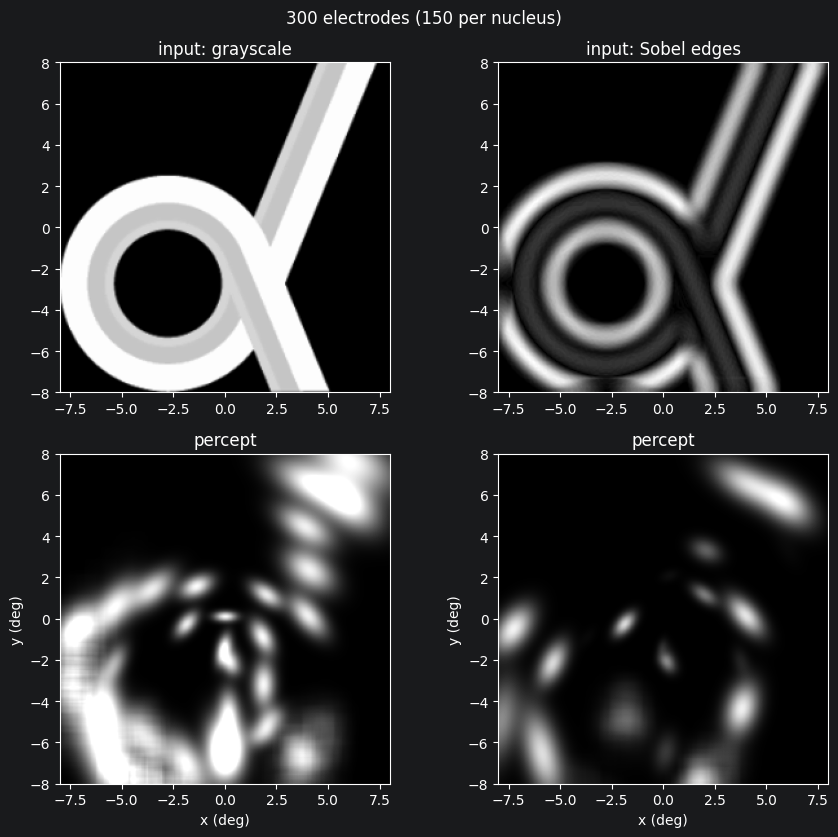

In [13]:
image_sim, _ = make_simulator(n_electrodes=150)

img = cv2.imread('../test/data/donders.png')[::-1]          # origin lower-left
gray = 255 - cv2.cvtColor(cv2.resize(img, (256, 256)), cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (21, 21), 7)
inputs = {'grayscale': gray, 'Sobel edges': sobel_processor(blur)}

fig, axs = plt.subplots(2, 2, figsize=(9, 8.5))
for column, (name, picture) in enumerate(inputs.items()):
    axs[0, column].imshow(picture, cmap='gray', origin='lower', extent=EXTENT)
    axs[0, column].set_title(f'input: {name}')
    # Normalize to [0, 1]; rescale=True then maps 1 onto 100 uA
    stim = image_sim.sample_stimulus(picture / picture.max(), rescale=True)
    image_sim.reset()
    show(axs[1, column], image_sim(stim), 'percept')
fig.suptitle(f'{image_sim.num_phosphenes} electrodes '
             f'({image_sim.num_phosphenes // 2} per nucleus)')
fig.tight_layout()

The filled logo drives many electrodes, and their fields add up into broad bright patches along the ring and the stroke. The edge map drives fewer of them, and more weakly. Most stay below the 52 µA threshold, so only the strongest edges appear, as scattered phosphenes. Edge detection is still the usual preprocessing step, because it keeps outlines rather than filled areas, but with this fixed rule much of the outline is lost. Section 8 learns the currents instead. The electrodes reach 8° from the center, the edge of the frame, so only the four corners of the image are never read.

**Do not forget `rescale=True`.** Without it, the sampled intensities (0 to 1) are read as amperes, so a white pixel becomes 1 A, ten thousand times the intended 100 µA. No warning is raised:

In [14]:
print(f"without rescale: max {image_sim.sample_stimulus(gray).max():.1e} A")
print(f"rescale=True   : max {image_sim.sample_stimulus(gray, rescale=True).max():.1e} A")

without rescale: max 8.4e-01 A
rescale=True   : max 8.4e-05 A


## 8. Optimizing the stimulation

Section 7 used a **fixed rule**: each electrode gets the brightest pixel in its receptive field, scaled to 100 µA, at the default 170 µs and 300 Hz. Nothing checks whether the percept that comes out looks like the image.

The simulator is written in PyTorch and every step is differentiable, so the currents can instead be **learned**. (The full end-to-end optimization used in the paper lives in [this repository](https://github.com/neuralcodinglab/viseon/tree/dynaphos-paper).)

#### 8a. Matching an image

We render the percept, compare it with the edge map (mean squared error, pixel by pixel), and let gradient descent adjust every electrode's current. Two details:

- The current is written as `100 µA × sigmoid(x)`, so it can never leave the 0–100 µA range the simulator was built for.
- Optimization starts from the fixed rule's currents, raised to at least 30 µA. That is below the 52 µA a lone electrode needs (section 3b), but an electrode also adds to its neighbors' summed field (section 11). So a weak electrode next to active ones still gets a gradient. One with no active neighbor gets none and never moves.

fixed rule : 21 of 300 electrodes above rheobase, median 56 uA, 5% of them above 90 uA
optimised  : 225 of 300 electrodes above rheobase, median 30 uA, 4% of them above 90 uA


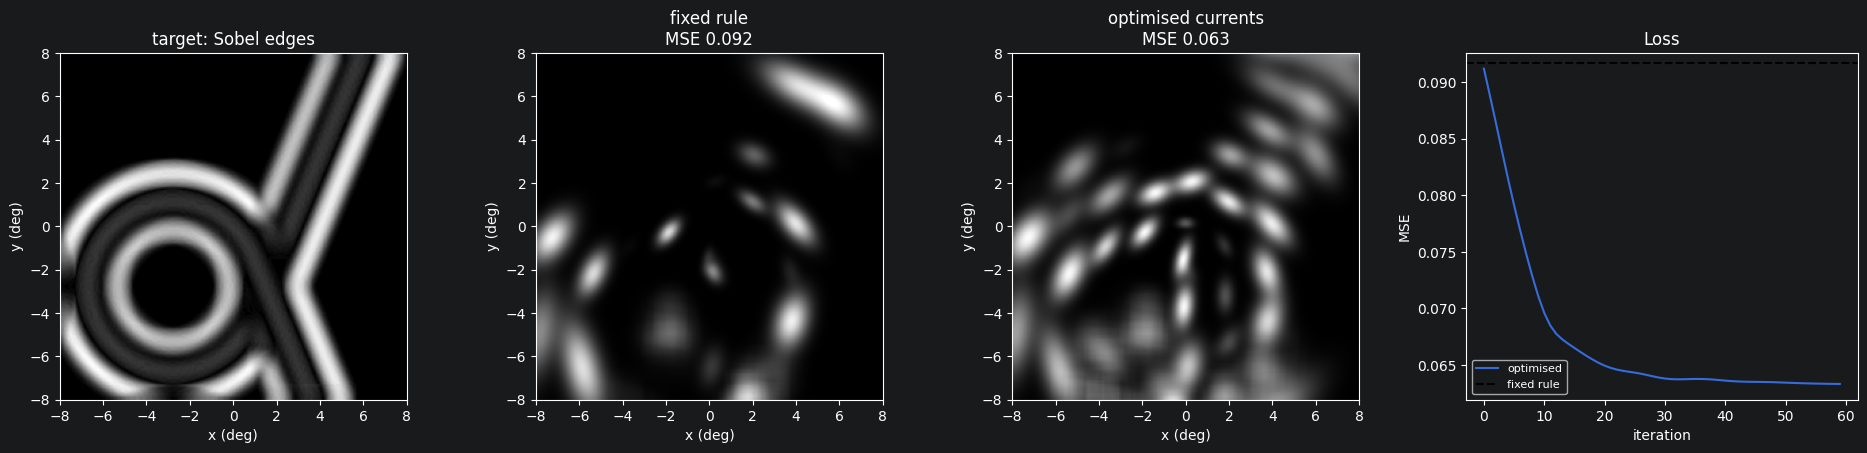

In [15]:
MAX_CURRENT = 100e-6
STIM = load_config()['default_stim']
# Below this current no charge reaches the tissue: the rheobase, raised for
# the default 170 us pulse by the chronaxie
ACTIVATION = load_config()['thresholding']['rheobase'] * (
    1 + STIM['chronaxie_s'] / STIM['pw_default'])
edges = inputs['Sobel edges'] / inputs['Sobel edges'].max()
target = torch.tensor(edges, dtype=torch.float32)


def mse(sim, stim):
    """Render `stim` and compare the percept with the target."""
    sim.reset()
    percept = sim(stim)
    # The percept lives on the simulator's device; bring the target to it
    return torch.nn.functional.mse_loss(percept, target.to(percept)), percept


def optimize(sim, steps=60):
    """Learn one current per electrode so the percept matches `target`."""
    fixed = sim.sample_stimulus(edges, rescale=True)
    start = fixed.clamp(30e-6, 0.95 * MAX_CURRENT) / MAX_CURRENT
    x = torch.nn.Parameter(torch.log(start / (1 - start)))   # sigmoid(x) = start
    optimizer = torch.optim.Adam([x], lr=0.1)
    losses = []
    for _ in range(steps):                                    # ~1 s per step
        optimizer.zero_grad()
        loss, _ = mse(sim, MAX_CURRENT * torch.sigmoid(x))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return fixed, (MAX_CURRENT * torch.sigmoid(x)).detach(), losses


fixed_stim, learned_stim, losses = optimize(image_sim)
fixed_loss, fixed_percept = mse(image_sim, fixed_stim)
fixed_loss = fixed_loss.item()
_, learned_percept = mse(image_sim, learned_stim)

fig, axs = plt.subplots(1, 4, figsize=(19, 4.5))
show(axs[0], target, 'target: Sobel edges')
show(axs[1], fixed_percept, f'fixed rule\nMSE {fixed_loss:.3f}')
show(axs[2], learned_percept, f'optimized currents\nMSE {losses[-1]:.3f}')
axs[3].plot(losses, label='optimized')
axs[3].axhline(fixed_loss, color='k', ls='--', label='fixed rule')
axs[3].set(xlabel='iteration', ylabel='MSE', title='Loss')
axs[3].legend(fontsize=8)
fig.tight_layout()

for name, stim in [('fixed rule', fixed_stim), ('optimized', learned_stim)]:
    image_sim.reset()
    image_sim(stim)
    detected = to_numpy(image_sim.get_state()['detection_probability']) > 0.5
    on = stim[stim > ACTIVATION]
    print(f'{name:<11}: {len(on)} of {len(stim)} electrodes above '
          f'{ACTIVATION * 1e6:.0f} uA (median {on.median() * 1e6:.0f} uA), '
          f'{detected.sum()} detected')

The optimized percept matches the edge map about 30% better (MSE 0.098 → 0.069). It gets there by switching many electrodes on **weakly**. Only 32 end above the 52 µA a lone electrode needs, but 219 are detected: their neighbors' summed fields carry them over threshold. The ring and the stroke come out as broad bright patches rather than lines. At the shipped K the phosphenes are too large to draw the hole in the ring.

This is still a toy. The loss compares pixels and the currents are fitted to this one image. A practical encoder would be a network trained over many images. The loss also need not be on the image: any quantity from `get_state()`, such as per-electrode brightness, works the same way.

#### 8b. What the gradients reach

The two nuclei are summed into one image, so one loss should reach the currents of both. A quick check:

In [16]:
image_sim.reset()
probe = torch.full((image_sim.num_phosphenes,), 80e-6, requires_grad=True)
image_sim(probe).sum().backward()
for name, span in image_sim.electrode_slices.items():
    print(f'{name:<5} LGN: |gradient| = {probe.grad[span].abs().sum():.3e}')

left  LGN: |gradient| = 3.261e+08
right LGN: |gradient| = 3.155e+08


Gradients reach amplitude, pulse width and frequency. They do not reach electrode positions, which are fixed at build time.

#### 8c. Soft or hard detection threshold

The percept is each phosphene's brightness times its **probability of being detected**. That probability compares the tissue activation with a per-electrode threshold, and `thresholding.soft_threshold` decides how:

- `True` (the default): a smooth logistic curve, as measured in detection experiments. It starts at 0 at zero activation and rises steadily.
- `False`: Dynaphos's original hard step, where a phosphene is either fully there or not there at all.

First, the curves themselves, for the three left-nucleus electrodes of the small array from section 6, all driven at the same current. The thresholds are drawn from the same seed, so both versions use the same thresholds.

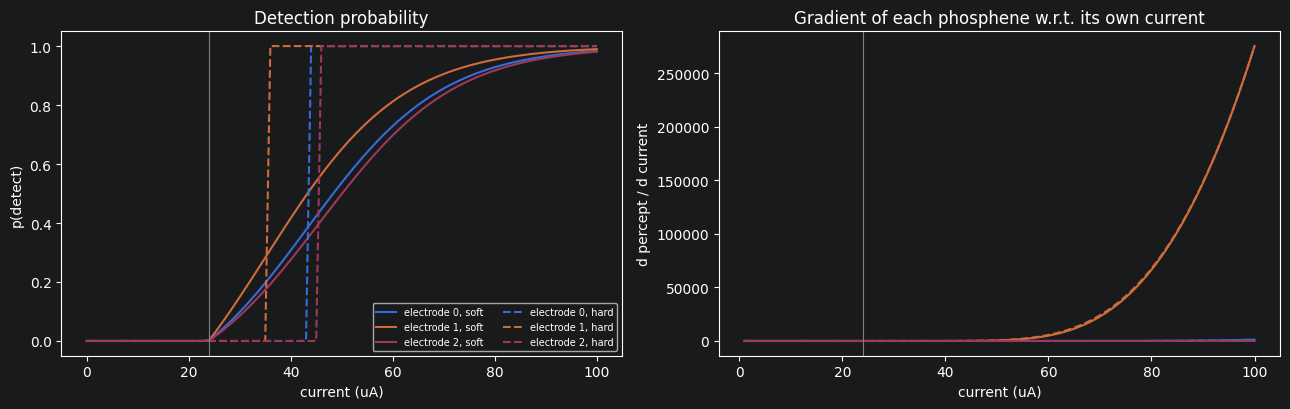

In [17]:
small_hard, _ = make_simulator(n_electrodes=3,
                               thresholding__soft_threshold=False)
currents = np.arange(0., 101., 1.)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for (gate, sim), style in zip({'soft': small, 'hard': small_hard}.items(),
                              ['-', '--']):
    p_detect, gradient = [], []
    for ua in currents:
        stim = torch.full((sim.num_phosphenes,), ua * 1e-6, requires_grad=True)
        sim.reset()
        sim(stim).sum().backward()
        p_detect.append(to_numpy(sim.get_state()['detection_probability']
                                 .detach()).ravel()[:3])
        gradient.append(to_numpy(stim.grad)[:3])
    for i in range(3):
        axs[0].plot(currents, np.array(p_detect)[:, i], style, color=f'C{i}',
                    label=f'electrode {i}, {gate}')
        axs[1].plot(currents, np.array(gradient)[:, i], style, color=f'C{i}')
for ax in axs:
    ax.axvline(ACTIVATION * 1e6, color='gray', lw=0.8)
    ax.set_xlabel('current (uA)')
axs[0].set(ylabel='p(detect)', title='Detection probability')
axs[0].legend(fontsize=7, ncol=2)
axs[1].set(ylabel='d percept / d current',
           title="Gradient of each phosphene w.r.t. its own current")
fig.tight_layout()

Both gates stay at zero below the activation current (gray line, 52 µA), where no charge reaches the tissue, and for a while above it. Then they differ:

- **Hard:** each electrode stays at 0 until its own threshold (64–74 µA here), then jumps to 1. Below that threshold the gradient is exactly **zero**, so an optimizer cannot tell that more current would help.
- **Soft:** detection and gradient start rising about 6 µA earlier (from 58–68 µA), so an electrode just below its threshold gets a signal too. The curve is steep, so it reaches full detection only a few µA after the step.

What that means in practice: the same image optimization as in 8a, once with each gate.

soft: 225 of 300 electrodes above rheobase, 33 of them detected
hard: 284 of 300 electrodes above rheobase, 45 of them detected


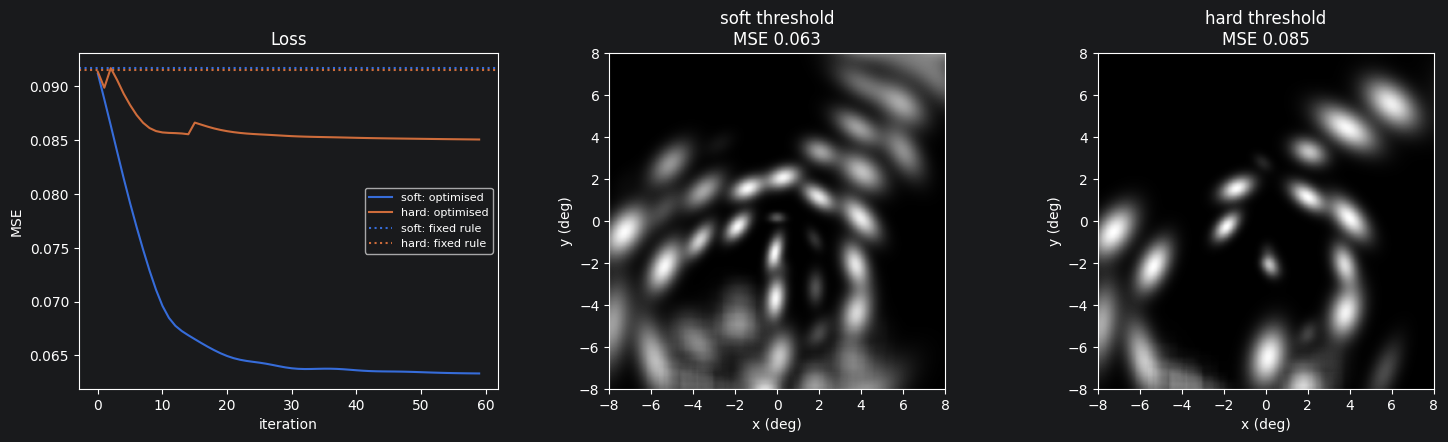

In [18]:
image_hard, _ = make_simulator(n_electrodes=150,
                               thresholding__soft_threshold=False)
fixed_hard, learned_hard, losses_hard = optimize(image_hard)
fixed_loss_hard = mse(image_hard, fixed_hard)[0].item()
_, learned_percept_hard = mse(image_hard, learned_hard)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for gate, curve, color in [('soft', losses, 'C0'), ('hard', losses_hard, 'C1')]:
    axs[0].plot(curve, color=color, label=f'{gate}: optimized')
axs[0].axhline(fixed_loss, color='C0', ls=':', label='soft: fixed rule')
axs[0].axhline(fixed_loss_hard, color='C1', ls=':', label='hard: fixed rule')
axs[0].set(xlabel='iteration', ylabel='MSE', title='Loss')
axs[0].legend(fontsize=8)
show(axs[1], learned_percept, f'soft threshold\nMSE {losses[-1]:.3f}')
show(axs[2], learned_percept_hard, f'hard threshold\nMSE {losses_hard[-1]:.3f}')
fig.tight_layout()

for gate, sim, stim in [('soft', image_sim, learned_stim),
                        ('hard', image_hard, learned_hard)]:
    sim.reset()
    sim(stim)
    detected = to_numpy(sim.get_state()['detection_probability']).ravel() > 0.5
    print(f'{gate}: {int((stim > ACTIVATION).sum())} of {len(stim)} electrodes '
          f'above {ACTIVATION * 1e6:.0f} uA, {detected.sum()} detected')

Here the two gates end level, at MSE 0.069 each. The printout shows why. Under either gate only about 32 electrodes end above 52 µA, yet about 220 are detected. Most of the percept comes from electrodes that their neighbors' fields carry over threshold, and that path passes a gradient through the equivalent current under both gates alike. The soft gate still passes a gradient just below each threshold, where the hard one passes none. That matters most when every electrode has to cross its threshold alone (`aggregation.mode: independent`).

The fixed rule happens to score the same under both gates here (MSE 0.098). The switch still changes the **model**, not just the optimizer, so say which one you used when reporting results.

## 9. Electrode level or tissue level

When several electrodes are on at once, their electric fields add up in the tissue. The `aggregation` section of the config decides what the simulator makes of that, and all three choices are still there:

| setting | level | what you see |
|---|---|---|
| `mode: independent` | electrode | each electrode recruits as if it were alone, as in Dynaphos |
| `mode: field_superposition`, `phosphene_merging: grown` | electrode | the fields add up, and each electrode keeps its own phosphene, grown by its equivalent current |
| `mode: field_superposition`, `phosphene_merging: merged` (default) | tissue | electrodes whose summed field recruits one connected volume of tissue appear as **one** phosphene, drawn from that tissue and as bright as its brightest member |

Field summation needs the pulses to overlap in time. With `aggregation.simultaneous_pulses: false` every setting falls back to independent.

Below, the 0.4 mm grid from section 5a under each setting.

setting         uA  lit area (deg2)   mean


independent     30              0.0  0.000
independent     60             11.5  0.012
independent    100             60.2  0.178


grown           30             73.2  0.222
grown           60             94.0  0.280
grown          100            103.9  0.313


merged          30             29.4  0.036
merged          60             33.6  0.043
merged         100             37.2  0.049


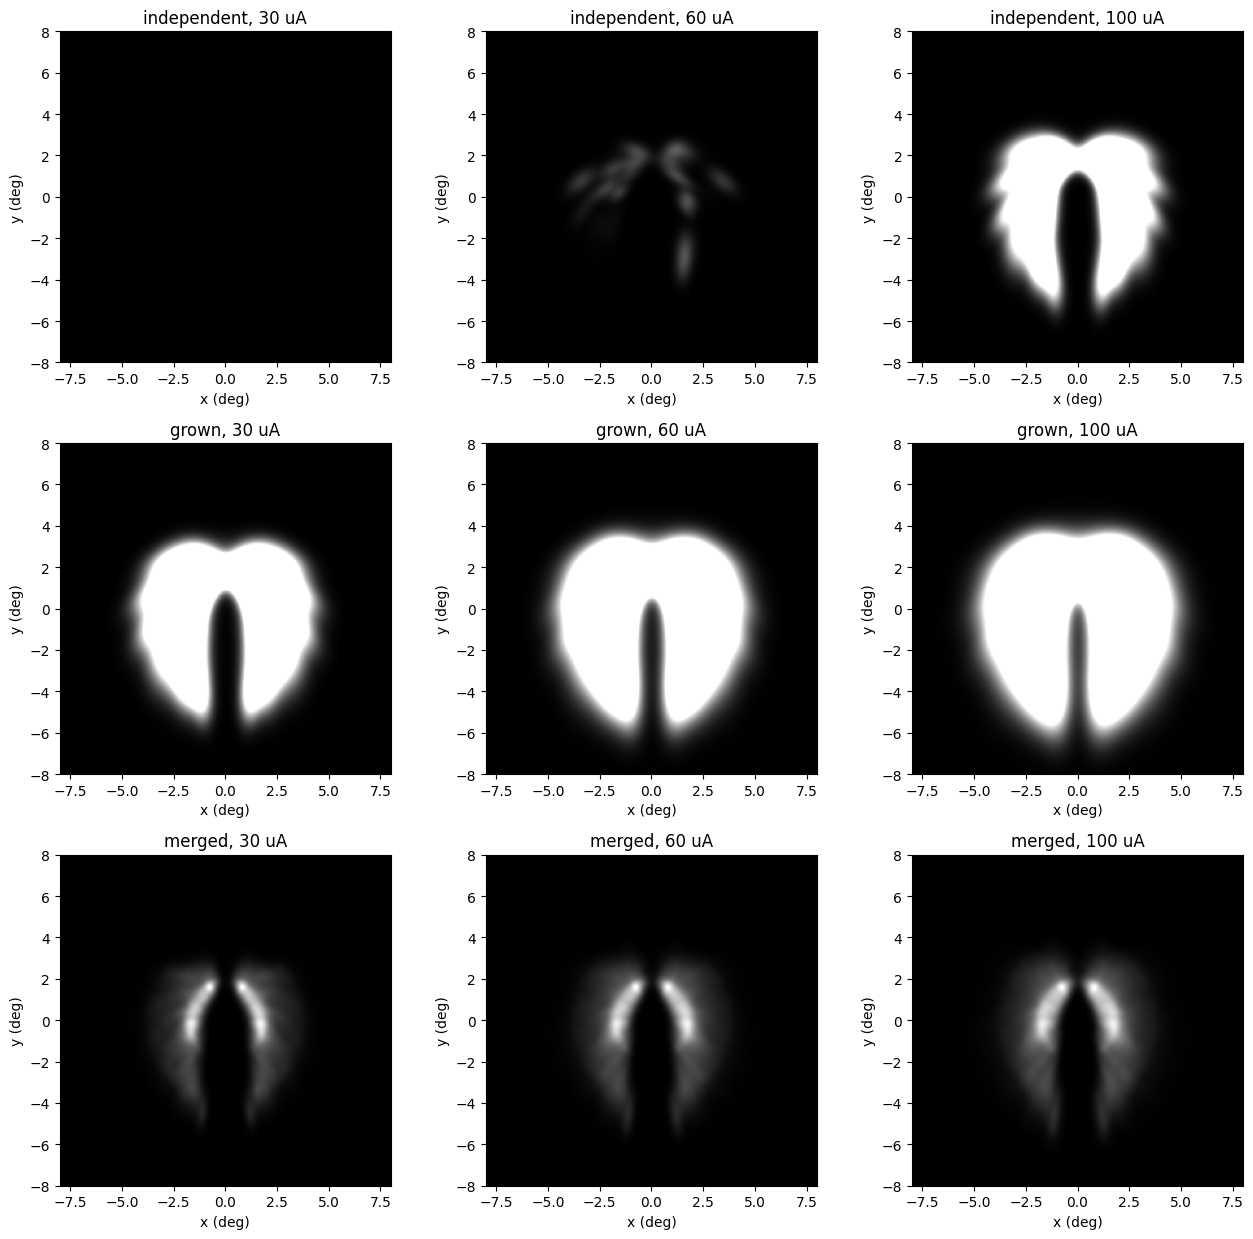

In [ ]:
AGGREGATION = {
    'independent': dict(aggregation__mode='independent'),
    'grown': dict(aggregation__mode='field_superposition',
                  aggregation__phosphene_merging='grown'),
    'merged': dict(aggregation__mode='field_superposition',
                   aggregation__phosphene_merging='merged'),
}
CURRENTS_UA = [30., 60., 100.]

fig, axs = plt.subplots(len(AGGREGATION), len(CURRENTS_UA),
                        figsize=(13, 12.5))
print(f'{"setting":<12} {"uA":>5} {"lit area (deg2)":>16} {"mean":>6}')
for row, (name, overrides) in zip(axs, AGGREGATION.items()):
    sim, _ = build_simulator(load_config(**overrides), atlas_dir=ATLAS_DIR,
                             voxel_indices=voxels)
    for ax, ua in zip(row, CURRENTS_UA):
        image = render(sim, ua)
        area = float((image > 0.1).float().mean()) * (2 * HALF) ** 2
        print(f'{name:<12} {ua:5.0f} {area:16.1f} {float(image.mean()):6.3f}')
        show(ax, image, f'{name}, {ua:.0f} uA')
fig.tight_layout()

The same stimulation gives three different percepts:

- **independent:** at 30 µA no charge reaches the tissue (a lone electrode needs about 52 µA at the default 170 µs pulse, section 3b), so nothing is seen. By 100 µA the separate phosphenes have grown into one another.
- **grown:** each electrode's neighbors raise its equivalent current far above its own, so at 30 µA every phosphene is already seen, and large. The phosphenes still add up, so they saturate into one white shape, larger than the independent one at 100 µA.
- **merged:** each nucleus's grid recruits one connected volume of tissue, so each half of the field shows a single phosphene. It takes the shape of that tissue in the visual field, and it is only as bright as its brightest member, so overlapping electrodes no longer stack up. More current adds tissue at its edges, so it grows slowly (29 to 37 deg² lit).

Nobody has tested whether co-recruited LGN tissue is seen as one phosphene, so treat the tissue level as a model choice. Switching `phosphene_merging` shows how much a result depends on it. Merging also costs time per frame. `aggregation.merge_lattice_mm` (0.05 mm) sets how finely the summed field is sampled, and a coarser lattice is faster.

#### 9b. Two electrodes: one phosphene or two

The grid hides what merging does to a single pair. Below, two electrodes in a parvocellular layer near 8 degrees eccentricity, at three spacings along the anteroposterior axis, each at the same current (45 µA, a little under a lone electrode's threshold). The table prints the brightest pixel within 0.3 degrees of each electrode's phosphene center.

In [ ]:
from scipy import ndimage

# Two electrodes deep inside a parvocellular layer near 8 deg, one on the
# anteroposterior axis (the third index) at increasing spacing.
parvo = np.isin(left.layer, [3, 4]) & left.valid
core = ndimage.binary_erosion(parvo, iterations=3)
near8 = np.argwhere(core & (np.abs(left.eccentricity_deg - 8) < 0.5))
base = near8[len(near8) // 2]
ecc, inc = left.eccentricity_deg[tuple(base)], left.inclination_deg[tuple(base)]
center = [ecc * np.cos(np.deg2rad(inc)) + 2.4, ecc * np.sin(np.deg2rad(inc)) + 0.6]

SPACINGS_MM = [0.2, 0.5, 1.0]
PAIR_UA = 45.
VOXEL_MM = 0.025
settings = {'merged': 'merged', 'grown': 'grown'}

fig, axs = plt.subplots(len(settings), len(SPACINGS_MM), figsize=(13, 8.5))
print(f'{"setting":<8} {"mm":>4} {"peak near electrode 1":>22} {"electrode 2":>12}')
for row, (name, merging) in zip(axs, settings.items()):
    for ax, mm in zip(row, SPACINGS_MM):
        pair = np.stack([base, base + [0, 0, round(mm / VOXEL_MM)]])
        params = load_config(aggregation__mode='field_superposition',
                             aggregation__phosphene_merging=merging,
                             run__view_angle=9., run__resolution=[256, 256],
                             run__origin=center)
        sim, _ = build_simulator(params, atlas_dir=ATLAS_DIR,
                                 voxel_indices={'left': pair},
                                 hemispheres=['left'])
        image = to_numpy(render(sim, PAIR_UA))
        # Highest pixel within 0.3 deg of each electrode's phosphene center
        peaks = []
        for x, y in sim.vf_xy:
            gx = np.linspace(center[0] - 4.5, center[0] + 4.5, image.shape[1])
            gy = np.linspace(center[1] - 4.5, center[1] + 4.5, image.shape[0])
            near = np.hypot(gx[None] - x, gy[:, None] - y) < 0.3
            peaks.append(image[near].max())
        print(f'{name:<8} {mm:4.1f} {peaks[0]:22.2f} {peaks[1]:12.2f}')
        ax.imshow(image, cmap='gray', origin='lower', vmin=0, vmax=1,
                  extent=[center[0] - 4.5, center[0] + 4.5,
                          center[1] - 4.5, center[1] + 4.5])
        ax.plot(*sim.vf_xy.T, '+', color='tab:orange', ms=10)
        ax.set(title=f'{name}, {mm:g} mm apart', xlabel='x (deg)',
               ylabel='y (deg)')
fig.tight_layout()

- **grown:** each electrode keeps its own phosphene. At 0.2 and 0.5 mm the two overlap, and both are bright (peaks 1.00 and 0.96 at 0.5 mm), because each has been raised by the other's field. At 1 mm the fields no longer reach each other, and the two electrodes act alone.
- **merged:** at 0.2 and 0.5 mm the recruited volumes touch, so the pair is drawn as **one** phosphene, scaled by the brighter member's brightness. The second electrode is only the shoulder of that blob, so its peak falls (0.94 against 0.46 at 0.5 mm) even though both electrodes carry the same current and have nearly the same equivalent current. The shoulder is dimmer because the same tissue spreads over more visual field there, so fewer recruited sites land under each pixel. At 1 mm the volumes are separate and the two settings agree.

So a brightness difference between two equally driven electrodes is a property of the merged rendering, not of the stimulation.

---

## Summary

- **The atlas sets the phosphenes.** Electrode position in the LGN fixes where each phosphene appears, how large it is, and its elliptical shape.
- **One nucleus covers half the field.** The whole field needs both (`atlas.hemispheres: [left, right]`), and the second nucleus is a mirror image of the first.
- **At the shipped parameters, phosphenes are large relative to their spacing.** Lowering the current barely helps and pulse width only changes brightness. The size depends mostly on K, the least certain number in the model.
- **Pulse width sets the threshold.** With the 200 µs chronaxie, charge reaches the tissue only above 52 µA at the default 170 µs pulse, 36 µA at 400 µs and 30 µA at 800 µs.
- **Electrodes can be placed three ways:** spread automatically, placed by tissue position, or placed by visual-field target.
- **Everything is differentiable** with respect to the stimulation parameters. Learning the currents against an image matches it better than sampling the image directly (MSE 0.098 → 0.069 here).
- **With summed fields, the optimizer works through neighbors.** Most electrodes it lights stay below their own threshold and are carried over it by their neighbors, so here the soft and hard gates end level. The soft gate still passes a gradient just below each threshold, where the hard one passes none.
- **Several electrodes merge at the tissue level by default.** Their fields add up, and electrodes that recruit one connected volume of tissue are seen as one phosphene. `aggregation.phosphene_merging: grown` and `aggregation.mode: independent` give the electrode-level alternatives.
